In [20]:
from typing import Iterable

import numpy as np
from matplotlib import pyplot as plt
import torch
import torch.nn as nn
import pennylane as qp

from mitiq.zne.scaling import fold_global
from mitiq.zne.inference import LinearFactory

from qiskit import transpile, QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from qiskit.circuit.library import ZFeatureMap, EfficientSU2
from qiskit.quantum_info import SparsePauliOp

from qiskit.primitives import BaseEstimatorV2, BackendEstimatorV2
from qiskit.primitives.containers import PrimitiveResult, PubResult
from qiskit.primitives.containers.estimator_pub import EstimatorPub

from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_algorithms.gradients import ReverseEstimatorGradient

from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2
from qiskit_ibm_runtime.options import EstimatorOptions
from qiskit.providers import JobStatus

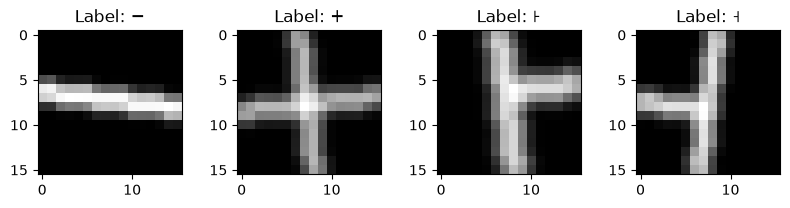

In [ ]:
#loading dataset
[pm] = qp.data.load('other', name='plus-minus')

X_train = pm.img_train  # shape (1000,16,16)
X_test = pm.img_test  # shape (200,16,16)
Y_train = pm.labels_train  # shape (1000,)
Y_test = pm.labels_test  # shape (200,)

x_vis = [
    (X_train[Y_train == 0])[0],
    (X_train[Y_train == 1])[0],
    (X_train[Y_train == 2])[0],
    (X_train[Y_train == 3])[0],
]
y_vis = [0, 1, 2, 3]

#visualizing each class
def visualize_data(x, y, pred=None):
    n_img = len(x)
    labels_list = ["\u2212", "\u002b", "\ua714", "\u02e7"]
    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    for i in range(n_img):
        axes[i].imshow(x[i], cmap="gray")
        if pred is None:
            axes[i].set_title("Label: {}".format(labels_list[y[i]]))
        else:
            axes[i].set_title("Label: {}, Pred: {}".format(labels_list[y[i]], labels_list[pred[i]]))
    plt.tight_layout(w_pad=2)
    plt.show()

visualize_data(x_vis, y_vis)

In [41]:
#prepare the noisy backend for the simulator
service = QiskitRuntimeService()
real_backend = service.least_busy(operational=True, simulator=False, min_num_qubits=8)
print(f"Target Real Backend: {real_backend.name}")

aer_backend = AerSimulator.from_backend(real_backend)
estimator = EstimatorV2(
    options={
        "backend_options": {
            "noise_model": aer_backend.options.noise_model,
            "method": "density_matrix",
        },
        "default_precision": 0.0,
    }
)

Target Real Backend: ibm_berlin


In [102]:
#noisy backend estimation ibm_berlin noise
class QiskitReuploadingClassifier(nn.Module):
    def __init__(self, input_dim=256, output_dim=4, num_qubits=8, num_layers=8, num_reup=3, estimator=estimator, backend=aer_backend):
        super().__init__()
        torch.manual_seed(1337)
        self.num_qubits = num_qubits
        self.output_dim = output_dim
        self.num_layers = num_layers
        self.num_reup = num_reup
        
        #3 rotations per qubit per layer
        self.total_angles = num_layers * num_qubits * 3
        self.input_projection = nn.Linear(input_dim, self.total_angles)
    
        self.weights = nn.Parameter(0.1 * torch.rand(self.total_angles))
        self.bias = nn.Parameter(0.1 * torch.rand(self.total_angles))
        
        self.qc, self.params = self._build_strongly_entangling_circuit()

        self.qc, self.params = self._build_strongly_entangling_circuit()

        if backend is not None:
            self.qc = transpile(
                self.qc,
                backend=backend,
                optimization_level=0,
            )

        self.observables = [
            SparsePauliOp.from_sparse_list(
                [("Z", [i], 1)],
                num_qubits=self.num_qubits,
            )
            for i in range(self.output_dim)
        ]

        if self.qc.layout is not None:
            self.observables = [
                obs.apply_layout(self.qc.layout)
                for obs in self.observables
            ]
            
        print(self.qc.num_qubits) 
        print(self.qc.num_parameters)
        qnn = EstimatorQNN(
            circuit=self.qc,
            observables=self.observables,
            input_params=self.params,
            weight_params=[],
            estimator=estimator,
            input_gradients=True,
            gradient=ReverseEstimatorGradient(),  
        )
        
        self.qcircuit = TorchConnector(qnn)

    def _build_strongly_entangling_circuit(self):
     qc = QuantumCircuit(self.num_qubits)
     params = ParameterVector('θ', self.total_angles)
        
     idx = 0
     for layer in range(self.num_layers):
        for q in range(self.num_qubits):
             qc.rz(params[idx], q)
             qc.ry(params[idx+1], q)
             qc.rz(params[idx+2], q)
             idx += 3
                
        step = (layer % (self.num_qubits - 1)) + 1
        for q in range(self.num_qubits):
            target = (q + step) % self.num_qubits
            qc.cx(q, target)
                
     return qc, params

    def forward(self, x):
        angles = self.input_projection(x)
        angles = self.weights * angles + self.bias
        return self.qcircuit(angles)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = QiskitReuploadingClassifier().to(device)

dummy_data = torch.rand(5, 256).to(device) 
output = model(dummy_data)

print("Output shape:", output.shape) # Expected: [5, 4]

Using device: cpu
120
192
Output shape: torch.Size([5, 4])


In [ ]:
#exact estimation no noise
class QiskitReuploadingClassifier(nn.Module):
    def __init__(self, input_dim=256, output_dim=4, num_qubits=8, num_layers=8, num_reup=3, estimator=None, backend=None):
        super().__init__()
        torch.manual_seed(1337)
        self.num_qubits = num_qubits
        self.output_dim = output_dim
        self.num_layers = num_layers
        self.num_reup = num_reup
        
        #3 rotations per qubit per layer
        self.total_angles = num_layers * num_qubits * 3
        self.input_projection = nn.Linear(input_dim, self.total_angles)
    
        self.weights = nn.Parameter(0.1 * torch.rand(self.total_angles))
        self.bias = nn.Parameter(0.1 * torch.rand(self.total_angles))
        
        self.qc, self.params = self._build_strongly_entangling_circuit()
        if backend is not None:
            self.qc = transpile(
                self.qc,
                backend=backend,
                optimization_level=0,
            )

        self.params = list(self.qc.parameters)
        
        self.observables = [SparsePauliOp.from_sparse_list([("Z", [i], 1)],num_qubits=self.num_qubits,) for i in range(self.output_dim)]

        if backend is not None and self.qc.layout is not None:
            self.observables = [
                obs.apply_layout(self.qc.layout)
                for obs in self.observables
            ]
        print(self.qc.num_qubits)
        print(self.qc.num_parameters)
        qnn = EstimatorQNN(
            circuit=self.qc,
            observables=self.observables,
            input_params=self.params,
            weight_params=[],
            estimator=estimator,
            input_gradients=True,
            gradient=ReverseEstimatorGradient(),  
        )
        
        self.qcircuit = TorchConnector(qnn)

    def _build_strongly_entangling_circuit(self):
     qc = QuantumCircuit(self.num_qubits)
     params = ParameterVector('θ', self.total_angles)
        
     idx = 0
     for layer in range(self.num_layers):
        for q in range(self.num_qubits):
             qc.rz(params[idx], q)
             qc.ry(params[idx+1], q)
             qc.rz(params[idx+2], q)
             idx += 3
                
        step = (layer % (self.num_qubits - 1)) + 1
        for q in range(self.num_qubits):
            target = (q + step) % self.num_qubits
            qc.cx(q, target)
                
     return qc, params

    def forward(self, x):
        angles = self.input_projection(x)
        angles = self.weights * angles + self.bias
        return self.qcircuit(angles)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = QiskitReuploadingClassifier().to(device)

dummy_data = torch.rand(5, 256).to(device) 
output = model(dummy_data)

print("Output shape:", output.shape) # Expected: [5, 4]

Using device: cpu
8
192
Output shape: torch.Size([5, 4])


In [ ]:
#instantiating the model
input_dim = 256
num_classes = 4
num_qubits = 8
num_layers = 8

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim, 
    output_dim=num_classes,     
    num_qubits=num_qubits, 
    num_layers=num_layers,
).to(device)


8
192


In [ ]:
# Hyperparameters 
learning_rate = 0.05
epochs = 3
batch_size = 20

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)
num_train = feats_train.shape[0]

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim, 
    output_dim=num_classes, 
    num_qubits=num_qubits, 
    num_layers=num_layers
).to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(qml_model.parameters(), lr=learning_rate)
num_batches = num_train // batch_size

def accuracy(labels, predictions):
    predicted_classes = torch.argmax(predictions, dim=1)
    correct = (predicted_classes == labels).sum().item()
    return correct / len(labels)

def gen_batches(num_samples, num_batches):
    assert num_samples % num_batches == 0
    perm_ind = torch.reshape(torch.randperm(num_samples), (num_batches, -1))
    return perm_ind


def print_acc(epoch, max_ep=4):
    with torch.no_grad():
        predictions_train = qml_model(feats_train[:50])
        predictions_test = qml_model(feats_test)
        
        cost_approx_train = loss(predictions_train, labels_train[:50])
        cost_approx_test = loss(predictions_test, labels_test)
        
        acc_approx_train = accuracy(labels_train[:50], predictions_train)
        acc_approx_test = accuracy(labels_test, predictions_test)
        
    print(
        f"Epoch {epoch}/{max_ep} | Approx Cost (train): {cost_approx_train:0.7f} | Cost (val): {cost_approx_test:0.7f} |"
        f" Approx Acc train: {acc_approx_train:0.7f} | Acc val: {acc_approx_test:0.7f}"
    )


8
192


Starting training loop for Qiskit variational classifier (8 qubits, 8 layers)...
Epoch 0/3 | Approx Cost (train): 1.3867089 | Cost (val): 1.3840621 | Approx Acc train: 0.2600000 | Acc val: 0.3600000
Epoch 1/3 | Approx Cost (train): 0.7856014 | Cost (val): 0.8210741 | Approx Acc train: 0.8600000 | Acc val: 0.8200000
Epoch 2/3 | Approx Cost (train): 0.6707109 | Cost (val): 0.6483303 | Approx Acc train: 0.9400000 | Acc val: 0.9800000
Epoch 3/3 | Approx Cost (train): 0.5955576 | Cost (val): 0.5905725 | Approx Acc train: 0.9600000 | Acc val: 0.9800000


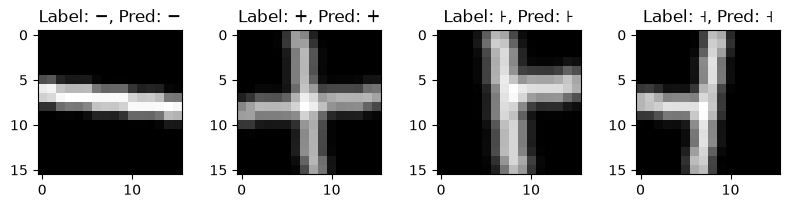

In [52]:
print(f"Starting training loop for Qiskit variational classifier ({num_qubits} qubits, {num_layers} layers)...")

for ep in range(epochs):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=epochs)

    for it in range(num_batches):
        optimizer.zero_grad()
        
        feats_train_batch = feats_train[batch_ind[it]]
        labels_train_batch = labels_train[batch_ind[it]]
        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs, max_ep=epochs)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

with torch.no_grad():
    benign_preds = qml_model(x_vis_torch)

benign_class_output = torch.argmax(benign_preds, dim=1).cpu().numpy()
visualize_data(x_vis, y_vis, benign_class_output)

In [65]:
save_path = "qiskit_reuploading_classifier_with_noise.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier_with_noise.pth


In [76]:
checkpoint = torch.load("qiskit_reuploading_classifier_after_attack_with_noise.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

qml_model.eval() 

with torch.no_grad():
    adversarial_preds_before = qml_model(feats_test)

adversarial_class_output_before = torch.argmax(adversarial_preds_before, dim=1)
acc = accuracy(labels_test, adversarial_preds_before)
print(f"Accuracy before PGD Attack: {acc:0.4f}")

Accuracy before PGD Attack: 1.0000


In [55]:
feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

In [ ]:
class _SynchronousJob:
    
    def __init__(self, result_data):
        self._result_data = result_data

    def result(self):
        return self._result_data
    
    def status(self):
        return JobStatus.DONE

class MitiqZNEEstimatorV2(BaseEstimatorV2):
    def __init__(self, backend, noise_factors=(1.0, 3.0, 5.0)):
        super().__init__()
        self.backend = backend 
        self.base_estimator = BackendEstimatorV2(backend=backend)
        self.noise_factors = noise_factors

    def run(self, pubs: Iterable, *, precision: float | None = None, **run_options):
        res = self._run_mitiq(pubs, precision=precision, **run_options)
        return _SynchronousJob(res)

    def _run_mitiq(self, pubs, precision=None, **run_options):
        coerced_pubs = [EstimatorPub.coerce(p) for p in pubs]
        all_folded_pubs = []
        batch_sizes = []
        
        for pub in coerced_pubs:
            circuit = pub.circuit
            observables = pub.observables
            bindings = pub.parameter_values
            
            b_size = bindings.shape[0] if bindings.shape else 1
            batch_sizes.append(b_size)
            
            for i in range(b_size):
                param_dict = {}
                for keys, val_array in bindings.data.items():
                    row_vals = val_array[i] if bindings.shape else val_array
                    
                    if isinstance(keys, tuple):
                        for k, v in zip(keys, row_vals):
                            param_dict[k] = v
                    else:
                        param_dict[keys] = row_vals
                        
                bound_qc = circuit.assign_parameters(param_dict, strict=False)
                
                for scale in self.noise_factors:
                    # folded_qc = fold_global(bound_qc, scale_factor=scale)
                    # transpiled_folded_qc = transpile(folded_qc, backend=self.backend, optimization_level=0)
                    # all_folded_pubs.append((transpiled_folded_qc, observables))
                    folded_qc = fold_global(bound_qc,scale_factor=scale,)
                    all_folded_pubs.append((folded_qc, observables))
                    
        base_job = self.base_estimator.run(all_folded_pubs, precision=precision, **run_options)
        base_result = base_job.result()
        
        final_results = []
        factory = LinearFactory(self.noise_factors)
        num_factors = len(self.noise_factors)
        
        def _extrapolate_1d(vals):
            return factory.extrapolate(self.noise_factors, vals)
            
        result_idx = 0
        
        for b_size in batch_sizes:
            mitigated_evs = []
            for _ in range(b_size):
                pub_results = base_result[result_idx : result_idx + num_factors]
                result_idx += num_factors
                
                evs_stack = np.array([res.data.evs for res in pub_results])
                mit_val = np.apply_along_axis(_extrapolate_1d, 0, evs_stack)
                mitigated_evs.append(mit_val)
                
            mitigated_evs = np.array(mitigated_evs)
            
            DataBinClass = type(base_result[0].data)
            kwargs = {"evs": mitigated_evs}
            if hasattr(base_result[0].data, "stds"):
                kwargs["stds"] = np.full_like(mitigated_evs, np.nan)
                
            new_data_bin = DataBinClass(**kwargs)
            final_results.append(PubResult(new_data_bin, metadata={"mitigated_by": "Mitiq_BoundBatch_Transpiled"}))
            
        return PrimitiveResult(final_results)


In [ ]:
# real_backend = service.least_busy(operational=True, simulator=False, min_num_qubits=8) 
# # print(f"Target Real Backend: {real_backend.name}") 
# # aer_backend = AerSimulator.from_backend(real_backend) 
# # print(f"Running on AerSimulator mimicking: {real_backend.name}") 
checkpoint = torch.load( "qiskit_reuploading_classifier_with_noise.pth", map_location=device, ) 
qml_model.load_state_dict(checkpoint["model_state_dict"]) 
service = QiskitRuntimeService() 
hardware_estimator = MitiqZNEEstimatorV2( backend=aer_backend, 
 noise_factors=[1.0, 3.0, 5.0], ) 

transpiled_qc = transpile( qml_model.qc, 
                          backend=aer_backend, 
                          optimization_level=0, ) 

hardware_model = QiskitReuploadingClassifier( input_dim=input_dim, 
                                             output_dim=num_classes, 
                                             num_qubits=num_qubits, 
                                             num_layers=num_layers, 
                                             estimator=hardware_estimator, 
                                             backend=aer_backend, )
hardware_model.qc = transpiled_qc 
hardware_model.load_state_dict(checkpoint["model_state_dict"]) 
hardware_model.eval()
with torch.no_grad(): 
    print("Mitiq ZNE ") 
    mitigated_predictions = hardware_model(perturbed_feats_test) 

mitigated_acc = accuracy(labels_test, mitigated_predictions) 
print(f"Simulated Mitigated Accuracy: {mitigated_acc:.4f}")

120
192
Începe evaluarea cu mitigare Mitiq ZNE (Local) ...
Simulated Mitigated Accuracy: 0.9000



After PGD Atack Vis_data:


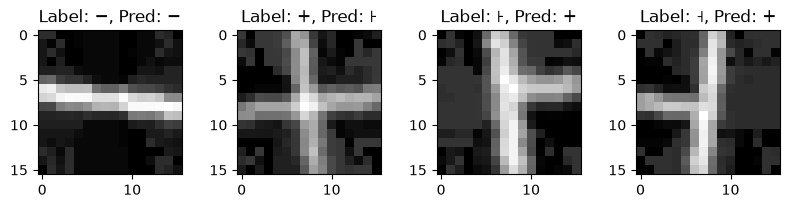

In [56]:

loss_fn = nn.CrossEntropyLoss()

def PGD(model, feats, labels, epsilon=0.05, alpha=0.01, num_iter=10):
    delta = torch.zeros_like(feats, requires_grad=True)
    
    for t in range(num_iter):
        feats_adv = feats + delta
        outputs = model(feats_adv)

        l = loss_fn(outputs, labels)
        l.backward()

        delta.data = (delta + alpha * delta.grad.detach().sign()).clamp(-epsilon, epsilon)
        delta.grad.zero_()
        
    return delta.detach()

perturbations = PGD(model=qml_model, feats=x_vis_torch, labels=y_vis_torch, epsilon=0.1)
perturbed_x = x_vis_torch + perturbations
qml_model.eval()
adversarial_preds_after = qml_model(perturbed_x)
adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)

print("\nAfter PGD Atack Vis_data:")
visualize_data(perturbed_x.cpu().detach().numpy().reshape(-1, 16, 16), y_vis, adversarial_class_output_after.cpu().numpy())


In [66]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05)
perturbed_feats_test = feats_test + perturbations_test


In [71]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.5600


In [83]:
adv_dataset = (
    PGD(model=qml_model, feats=feats_train[:50], labels=labels_train[:50], epsilon=0.5)
    + feats_train[:50]
)

feats_retrain = torch.cat((feats_train, adv_dataset))
labels_retrain = torch.cat((labels_train, labels_train[:50]))
epochs_retraining = 3

for ep in range(0, epochs_retraining):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=3)

    for it in range(num_batches):
        optimizer.zero_grad()
        feats_train_batch = feats_retrain[batch_ind[it]]
        labels_train_batch = labels_retrain[batch_ind[it]]

        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        # if REG:
        #    loss = loss + lipschitz_regularizer(regularization_rate, model.qcircuit.weights)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs_retraining, max_ep=3)

save_path = "qiskit_reuploading_classifier_after_attack_with_noise.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Epoch 0/3 | Approx Cost (train): 0.5137163 | Cost (val): 0.5312364 | Approx Acc train: 0.9800000 | Acc val: 0.9800000
Epoch 1/3 | Approx Cost (train): 0.4926308 | Cost (val): 0.5113609 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Epoch 2/3 | Approx Cost (train): 0.4834202 | Cost (val): 0.5096074 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Epoch 3/3 | Approx Cost (train): 0.4755773 | Cost (val): 0.4937195 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Model weights saved to qiskit_reuploading_classifier_after_attack_with_noise.pth



Dupa atac:


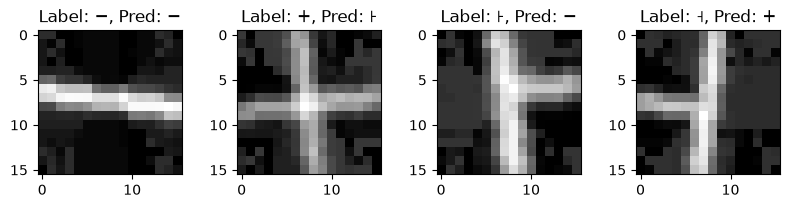

In [ ]:
qml_model.eval()
adversarial_preds_after = qml_model(perturbed_x)
adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)

print("\nDupa atac:")
visualize_data(perturbed_x.cpu().detach().numpy().reshape(-1, 16, 16), y_vis, adversarial_class_output_after.cpu().numpy())

In [84]:
checkpoint = torch.load(
    "qiskit_reuploading_classifier_after_attack_with_noise.pth",
    map_location=device,
)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

In [85]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05)
perturbed_feats_test = feats_test + perturbations_test


In [88]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.5800
